# Cluster portfolios

Each clustering produces 11 groups of stocks per rebal date. The simplest portfolio rule on top of that is: pick one stock per cluster, and equal-weight across the 11 picks. That's what this notebook does.

Three portfolios built (the scripts that produced them live in `scripts/build_cluster_portfolios.py`):

- `q2_cluster_K11`: Q2 (sector-beta residual) clusters. The "primary" candidate.
- `q1_cluster_K11`: Q1 (CAPM residual) clusters. Baseline.
- `q0direct_cluster_K11`: clusters on raw 252-day return vectors. Naive baseline.

Selection rule: centroid pick. Within each cluster, the stock whose feature vector is closest (Euclidean) to the cluster centroid (in the same scaled space the clustering operated on).
Weighting: equal across the 11 cluster representatives, 1/11 each.
Rebalance: monthly (290 dates from 2002 to 2026).
Return aggregation: simple-return space, then logged. Summing weight times log-return is incorrect for large constituent moves and was a real bug in the first version of this code.

I include an equal-weight S&P 500 portfolio as a reference (not a fair baseline, more of a sanity-check reference). The full baseline-portfolio comparison (HRP, Markowitz, GICS-stratified) lives in the baseline-portfolios notebook.


## 1. Setup


In [1]:
import numpy as np
import pandas as pd
import arcticdb as adb
import matplotlib.pyplot as plt
%matplotlib inline
from pathlib import Path

ARCTIC_URI = "lmdb://./database/arctic"
ac = adb.Arctic(ARCTIC_URI)
portfolios_lib = ac["portfolios_lib"]
stocks_lib     = ac["stocks_lib"]
removed_lib    = ac["removed_stocks"]
metadata_lib   = ac["metadata_lib"]
OUTPUTS = Path("outputs"); OUTPUTS.mkdir(exist_ok=True)


## 2. Load the three cluster portfolios

Each portfolio in `portfolios_lib` is stored as two symbols: `_holdings` (rebal_date x ticker x weight) and `_returns` (daily log returns). Both are persisted by the build script; here I just read them.


In [2]:
PORTFOLIOS = ["q2_cluster_K11", "q1_cluster_K11", "q0direct_cluster_K11"]
LABELS = {
    "q2_cluster_K11":       "Q2 sector-beta residual",
    "q1_cluster_K11":       "Q1 CAPM residual",
    "q0direct_cluster_K11": "Q0 direct (raw 252d)",
    "ew_sp500":             "EW S&P 500 (reference)",
}
COLORS = {
    "q2_cluster_K11":       "orange",
    "q1_cluster_K11":       "steelblue",
    "q0direct_cluster_K11": "tab:gray",
    "ew_sp500":             "black",
}

portfolio_returns  = {}
portfolio_holdings = {}
for p in PORTFOLIOS:
    portfolio_returns[p]  = portfolios_lib.read(f"{p}_returns").data["ret"]
    portfolio_holdings[p] = portfolios_lib.read(f"{p}_holdings").data
    r = portfolio_returns[p]
    print(f"{p:<25}  {r.index.min().date()} to {r.index.max().date()}  "
          f"({len(r)} days)  cum log = {r.cumsum().iloc[-1]:+.2f}")


q2_cluster_K11             2002-01-02 to 2026-02-13  (6069 days)  cum log = +1.54
q1_cluster_K11             2002-01-02 to 2026-02-13  (6069 days)  cum log = +2.13
q0direct_cluster_K11       2002-01-02 to 2026-02-13  (6069 days)  cum log = +2.20


## 3. Build the EW S&P 500 reference

For each day, equal-weight average of simple returns across all stocks in the membership-masked panel that day. Then log. This is the same universe and the same survivorship-bias-free setup as everywhere else in the project.


In [3]:
def membership_mask(intervals, dates, tickers):
    tickers = pd.Index(tickers)
    mask = pd.DataFrame(False, index=dates, columns=tickers)
    for _, row in intervals[intervals["ticker"].isin(tickers)].iterrows():
        t = row["ticker"]
        start = row["start"] if pd.notna(row["start"]) else dates.min()
        end   = row["end"]   if pd.notna(row["end"])   else dates.max()
        mask.loc[(dates >= start) & (dates <= end), t] = True
    return mask


intervals = metadata_lib.read("sp500_membership").data
series = []
for lib in (stocks_lib, removed_lib):
    for item in lib.read_batch(lib.list_symbols()):
        if "closeadj" in item.data.columns and not item.data["closeadj"].isna().all():
            series.append(item.data["closeadj"].rename(item.symbol))
prices = pd.concat(series, axis=1).sort_index()
prices = prices.loc[:, ~prices.columns.duplicated()]
prices = prices.where(membership_mask(intervals, prices.index, prices.columns))

log_returns = np.log(prices / prices.shift(1))
simple = np.expm1(log_returns)
ew_simple = simple.mean(axis=1, skipna=True)
ew_log = np.log1p(ew_simple)

start_date = min(r.index.min() for r in portfolio_returns.values())
end_date   = max(r.index.max() for r in portfolio_returns.values())
ew_log = ew_log.loc[start_date:end_date].dropna()
portfolio_returns["ew_sp500"] = ew_log
print(f"EW S&P 500 reference: {ew_log.index.min().date()} to {ew_log.index.max().date()}  "
      f"({len(ew_log)} days)  cum log = {ew_log.cumsum().iloc[-1]:+.2f}")


EW S&P 500 reference: 2002-01-02 to 2026-02-13  (6069 days)  cum log = +2.49


## 4. Equity curves and drawdowns

Two-panel plot. Top: cumulative log return for each portfolio plus the EW reference. Bottom: log drawdown from peak (underwater plot). Crisis markers for context.


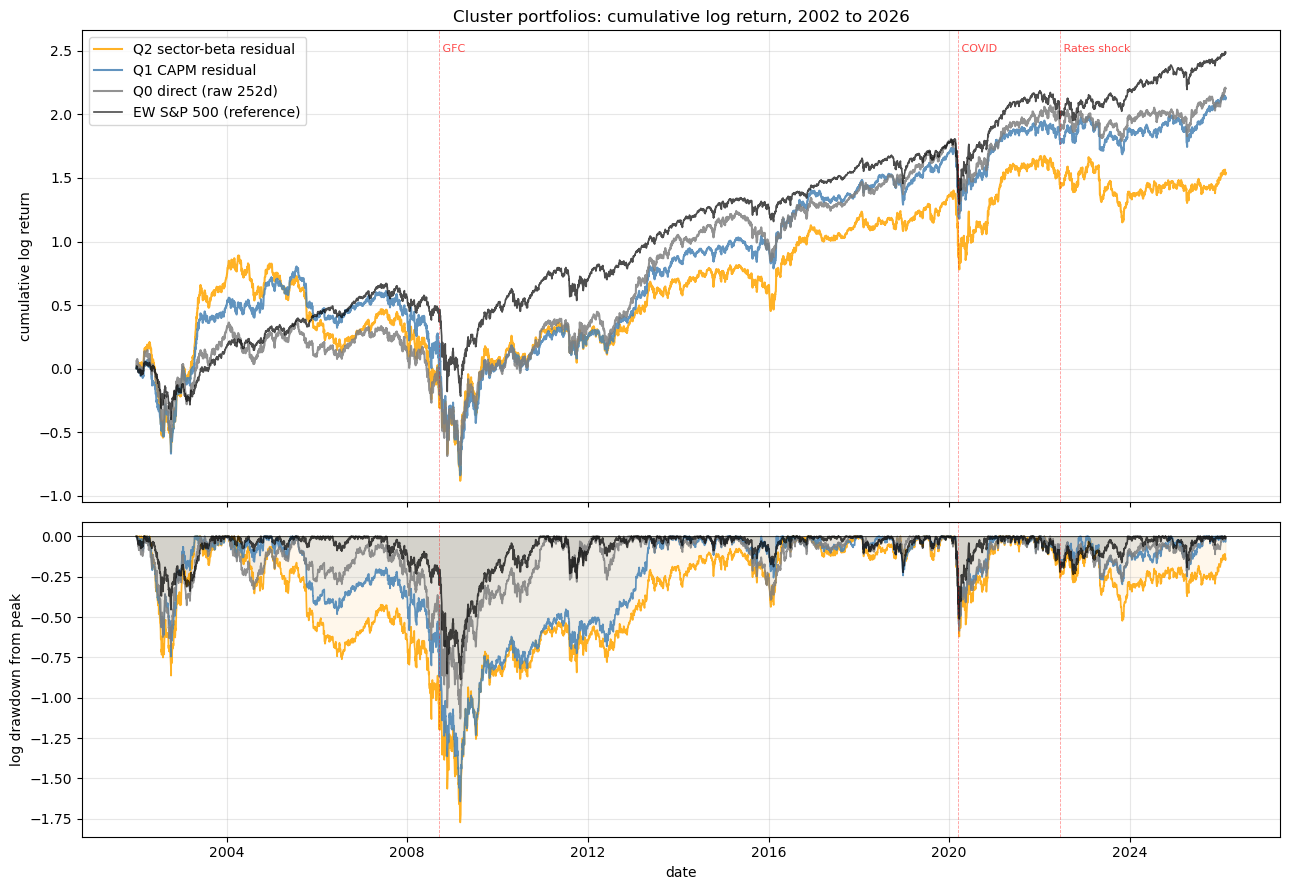

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True,
                          gridspec_kw={"height_ratios": [3, 2]})

# Top: cumulative log return
for p in PORTFOLIOS + ["ew_sp500"]:
    r = portfolio_returns[p]
    axes[0].plot(r.index, r.cumsum(), label=LABELS[p], color=COLORS[p],
                  lw=1.5 if p != "ew_sp500" else 1.2,
                  alpha=0.85 if p != "ew_sp500" else 0.7)
axes[0].set_ylabel("cumulative log return")
axes[0].set_title("Cluster portfolios: cumulative log return, 2002 to 2026")
axes[0].legend(loc="upper left", fontsize=10)
axes[0].grid(alpha=0.3)

# Bottom: drawdown
for p in PORTFOLIOS + ["ew_sp500"]:
    cum = portfolio_returns[p].cumsum()
    dd = cum - cum.cummax()
    axes[1].plot(dd.index, dd, label=LABELS[p], color=COLORS[p],
                  lw=1.2, alpha=0.85 if p != "ew_sp500" else 0.7)
    axes[1].fill_between(dd.index, dd, 0, color=COLORS[p], alpha=0.08)
axes[1].axhline(0, color="black", lw=0.5)
axes[1].set_ylabel("log drawdown from peak")
axes[1].set_xlabel("date")
axes[1].grid(alpha=0.3)

for x, lab in [("2008-09-15", "GFC"), ("2020-03-15", "COVID"),
                ("2022-06-15", "Rates shock")]:
    for ax in axes:
        ax.axvline(pd.Timestamp(x), color="red", lw=0.6, alpha=0.4, ls="--")
    axes[0].text(pd.Timestamp(x), axes[0].get_ylim()[1] * 0.96, " " + lab,
                  color="red", fontsize=8, alpha=0.7, va="top")
fig.tight_layout()
fig.savefig("outputs/cluster_portfolios_equity.png", dpi=130)
plt.show()


## 5. Headline stats

Annualized log return (CAGR), annualized vol, Sharpe (zero risk-free), max log-drawdown, Calmar (CAGR / |max DD|), and average per-rebal turnover. Turnover is computed as `|prev_holdings symmetric_diff curr_holdings| / (2 * len(prev_holdings))`, so 0% = same names every month, 100% = totally different names.


In [5]:
ANN = 252


def stats_row(name, r):
    cum = r.cumsum()
    dd = (cum - cum.cummax()).min()
    cagr = r.mean() * ANN
    vol  = r.std() * np.sqrt(ANN)
    sharpe = cagr / vol if vol > 0 else float("nan")
    calmar = cagr / -dd if dd < 0 else float("nan")
    return {"portfolio": LABELS[name], "CAGR_log": cagr, "vol_ann": vol,
            "Sharpe": sharpe, "max_log_DD": dd, "Calmar": calmar}


def avg_turnover(holdings):
    rebal_dates = sorted(holdings.index.get_level_values(0).unique())
    rotations = []
    for prev, curr in zip(rebal_dates[:-1], rebal_dates[1:]):
        prev_set = set(holdings.xs(prev, level=0).index)
        curr_set = set(holdings.xs(curr, level=0).index)
        if not prev_set:
            continue
        rotated = len(prev_set.symmetric_difference(curr_set)) / (2 * len(prev_set))
        rotations.append(rotated)
    return float(np.mean(rotations)) if rotations else float("nan")


rows = []
for p in PORTFOLIOS:
    row = stats_row(p, portfolio_returns[p])
    row["turnover_per_rebal"] = avg_turnover(portfolio_holdings[p])
    rows.append(row)
rows.append({**stats_row("ew_sp500", portfolio_returns["ew_sp500"]),
              "turnover_per_rebal": float("nan")})

stats_df = pd.DataFrame(rows)
for c in ["CAGR_log", "vol_ann", "max_log_DD"]:
    stats_df[c] = stats_df[c].map(lambda x: f"{x:+.2%}")
stats_df["Sharpe"] = stats_df["Sharpe"].map(lambda x: f"{x:+.2f}")
stats_df["Calmar"] = stats_df["Calmar"].map(lambda x: f"{x:.2f}" if pd.notna(x) else "n/a")
stats_df["turnover_per_rebal"] = stats_df["turnover_per_rebal"].map(
    lambda x: f"{x:.1%}" if pd.notna(x) else "n/a"
)
stats_df = stats_df[["portfolio", "CAGR_log", "vol_ann", "Sharpe",
                     "max_log_DD", "Calmar", "turnover_per_rebal"]]
print(stats_df.to_string(index=False))
stats_df.to_csv("outputs/cluster_portfolios_stats.csv", index=False)
print("\nwrote outputs/cluster_portfolios_stats.csv")


              portfolio CAGR_log vol_ann Sharpe max_log_DD Calmar turnover_per_rebal
Q2 sector-beta residual   +6.39% +29.70%  +0.22   -177.22%   0.04              60.2%
       Q1 CAPM residual   +8.85% +27.01%  +0.33   -164.25%   0.05              61.9%
   Q0 direct (raw 252d)   +9.14% +26.77%  +0.34   -112.95%   0.08              57.7%
 EW S&P 500 (reference)  +10.33% +20.88%  +0.49    -88.69%   0.12                n/a

wrote outputs/cluster_portfolios_stats.csv


## 6. Spot-check the latest holdings

Just to confirm the centroid pick is producing reasonable names, list the 11 picks for each portfolio on the most recent rebal date, with their GICS sector for readability.


In [6]:
latest = portfolio_holdings["q2_cluster_K11"].index.get_level_values(0).max()
print(f"Latest rebal date: {latest.date()}\n")

ticker_sector = {}
for lib in (stocks_lib, removed_lib):
    for sym in lib.list_symbols():
        meta = lib.read_metadata(sym).metadata or {}
        if meta.get("sector"):
            ticker_sector[sym] = meta["sector"]

for p in PORTFOLIOS:
    if latest not in portfolio_holdings[p].index.get_level_values(0):
        continue
    h = portfolio_holdings[p].xs(latest, level=0).copy()
    h["sector"] = [ticker_sector.get(t, "?") for t in h.index]
    print(f"=== {LABELS[p]} ===")
    print(h.sort_values("cluster_id").to_string())
    print()


Latest rebal date: 2026-01-30

=== Q2 sector-beta residual ===
        cluster_id    weight                  sector
ticker                                              
WDC              0  0.090909              Technology
ELV              1  0.090909              Healthcare
SCHW             2  0.090909      Financial Services
ADSK             3  0.090909              Technology
ULTA             4  0.090909       Consumer Cyclical
INTC             5  0.090909              Technology
FSLR             6  0.090909              Technology
BDX              7  0.090909              Healthcare
PSKY             8  0.090909  Communication Services
KIM              9  0.090909             Real Estate
CMS             10  0.090909               Utilities

=== Q1 CAPM residual ===
        cluster_id    weight                  sector
ticker                                              
VICI             0  0.090909             Real Estate
BDX              1  0.090909              Healthcare
ETN       

## What this tells me

The headline ranking on Sharpe is the opposite of what the project's design loosely hypothesized:

- Q0_direct beats Q1 beats Q2 among the cluster portfolios.
- None of the cluster portfolios beat the EW S&P 500 reference on Sharpe.

Informal explanation, based on the holdings spot-check and the sector-PCR breakdown in the risk-decomposition notebook:

- Q0 direct clusters implicitly bucket stocks by volatility / beta tier. The centroid pick of each tier is a "typical" name in that vol bucket. The portfolio ends up volatility-diversified across 11 risk buckets, which behaves like a defensive tilt.
- Q1 clusters mostly track GICS sectors (this is the ARI result from the eval notebook). One-stock-per-sector picks resemble a GICS-stratified portfolio with one sample per sector. Diversification is okay but selection within sectors is not deliberately tilted for risk.
- Q2 clusters strip the sector signal and pick up sub-sector / idiosyncratic structure. Centroid picks within idiosyncratic clusters concentrate in high-specific-risk names. That hurts Sharpe.

The big-picture conclusion: clustering picks up real structure (the eval notebook proved that), but turning that structure into a naive 1-per-cluster equal-weight portfolio doesn't beat the simple baselines. The baseline-portfolios notebook will show that PCA used as a covariance-matrix FILTER (rather than a cluster labeler) does much better.
